In [1]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid')
np.random.seed(42)

In [2]:
# 2.1 Load the raw FIFA dataset
df = pd.read_csv('../datasets/fifa.csv')

print('Dataset Shape:', df.shape)
print('\nColumn Names:')
print(df.columns.tolist())
print('\nData Types:')
print(df.dtypes.value_counts())
print('\nMissing Values:')
print(df.isnull().sum().sum())
print('\nDuplicate Rows:', df.duplicated().sum())
print('\nTarget Summary:')
print(df['performance_score'].describe())

Dataset Shape: (54600, 75)

Column Names:
['player_id', 'player_name', 'age', 'nationality', 'team', 'jersey_number', 'position', 'height_cm', 'weight_kg', 'preferred_foot', 'club_name', 'market_value_eur', 'match_id', 'match_date', 'stadium', 'city', 'opponent_team', 'tournament_stage', 'match_result', 'goals_team', 'goals_opponent', 'minutes_played', 'goals', 'assists', 'shots', 'shots_on_target', 'expected_goals_xg', 'expected_assists_xa', 'key_passes', 'successful_passes', 'total_passes', 'pass_accuracy', 'dribbles_attempted', 'successful_dribbles', 'crosses', 'successful_crosses', 'tackles', 'interceptions', 'clearances', 'blocks', 'aerial_duels_won', 'aerial_duels_lost', 'recoveries', 'defensive_actions', 'fouls_committed', 'fouls_suffered', 'yellow_cards', 'red_cards', 'offsides', 'saves', 'save_percentage', 'punches', 'clean_sheet', 'goals_conceded', 'penalty_saves', 'distance_covered_km', 'sprint_distance_km', 'top_speed_kmh', 'accelerations', 'decelerations', 'stamina_score',

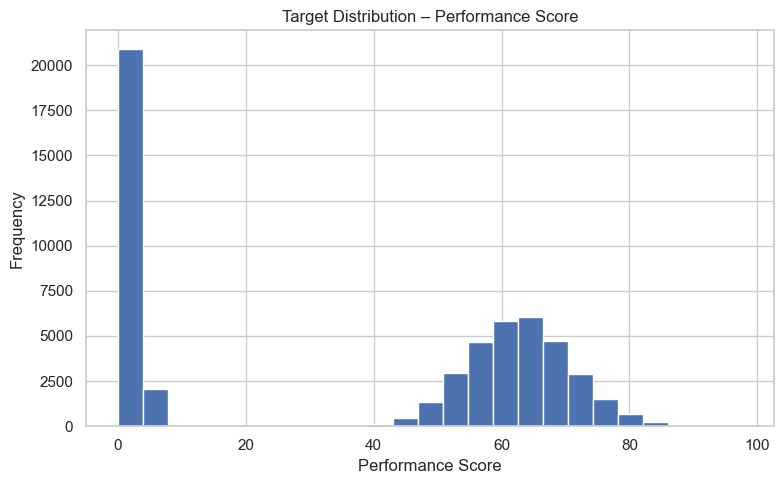

In [3]:
# 2.2 Target distribution
plt.figure(figsize=(8,5))
plt.hist(df['performance_score'], bins=25)
plt.title('Target Distribution – Performance Score')
plt.xlabel('Performance Score')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

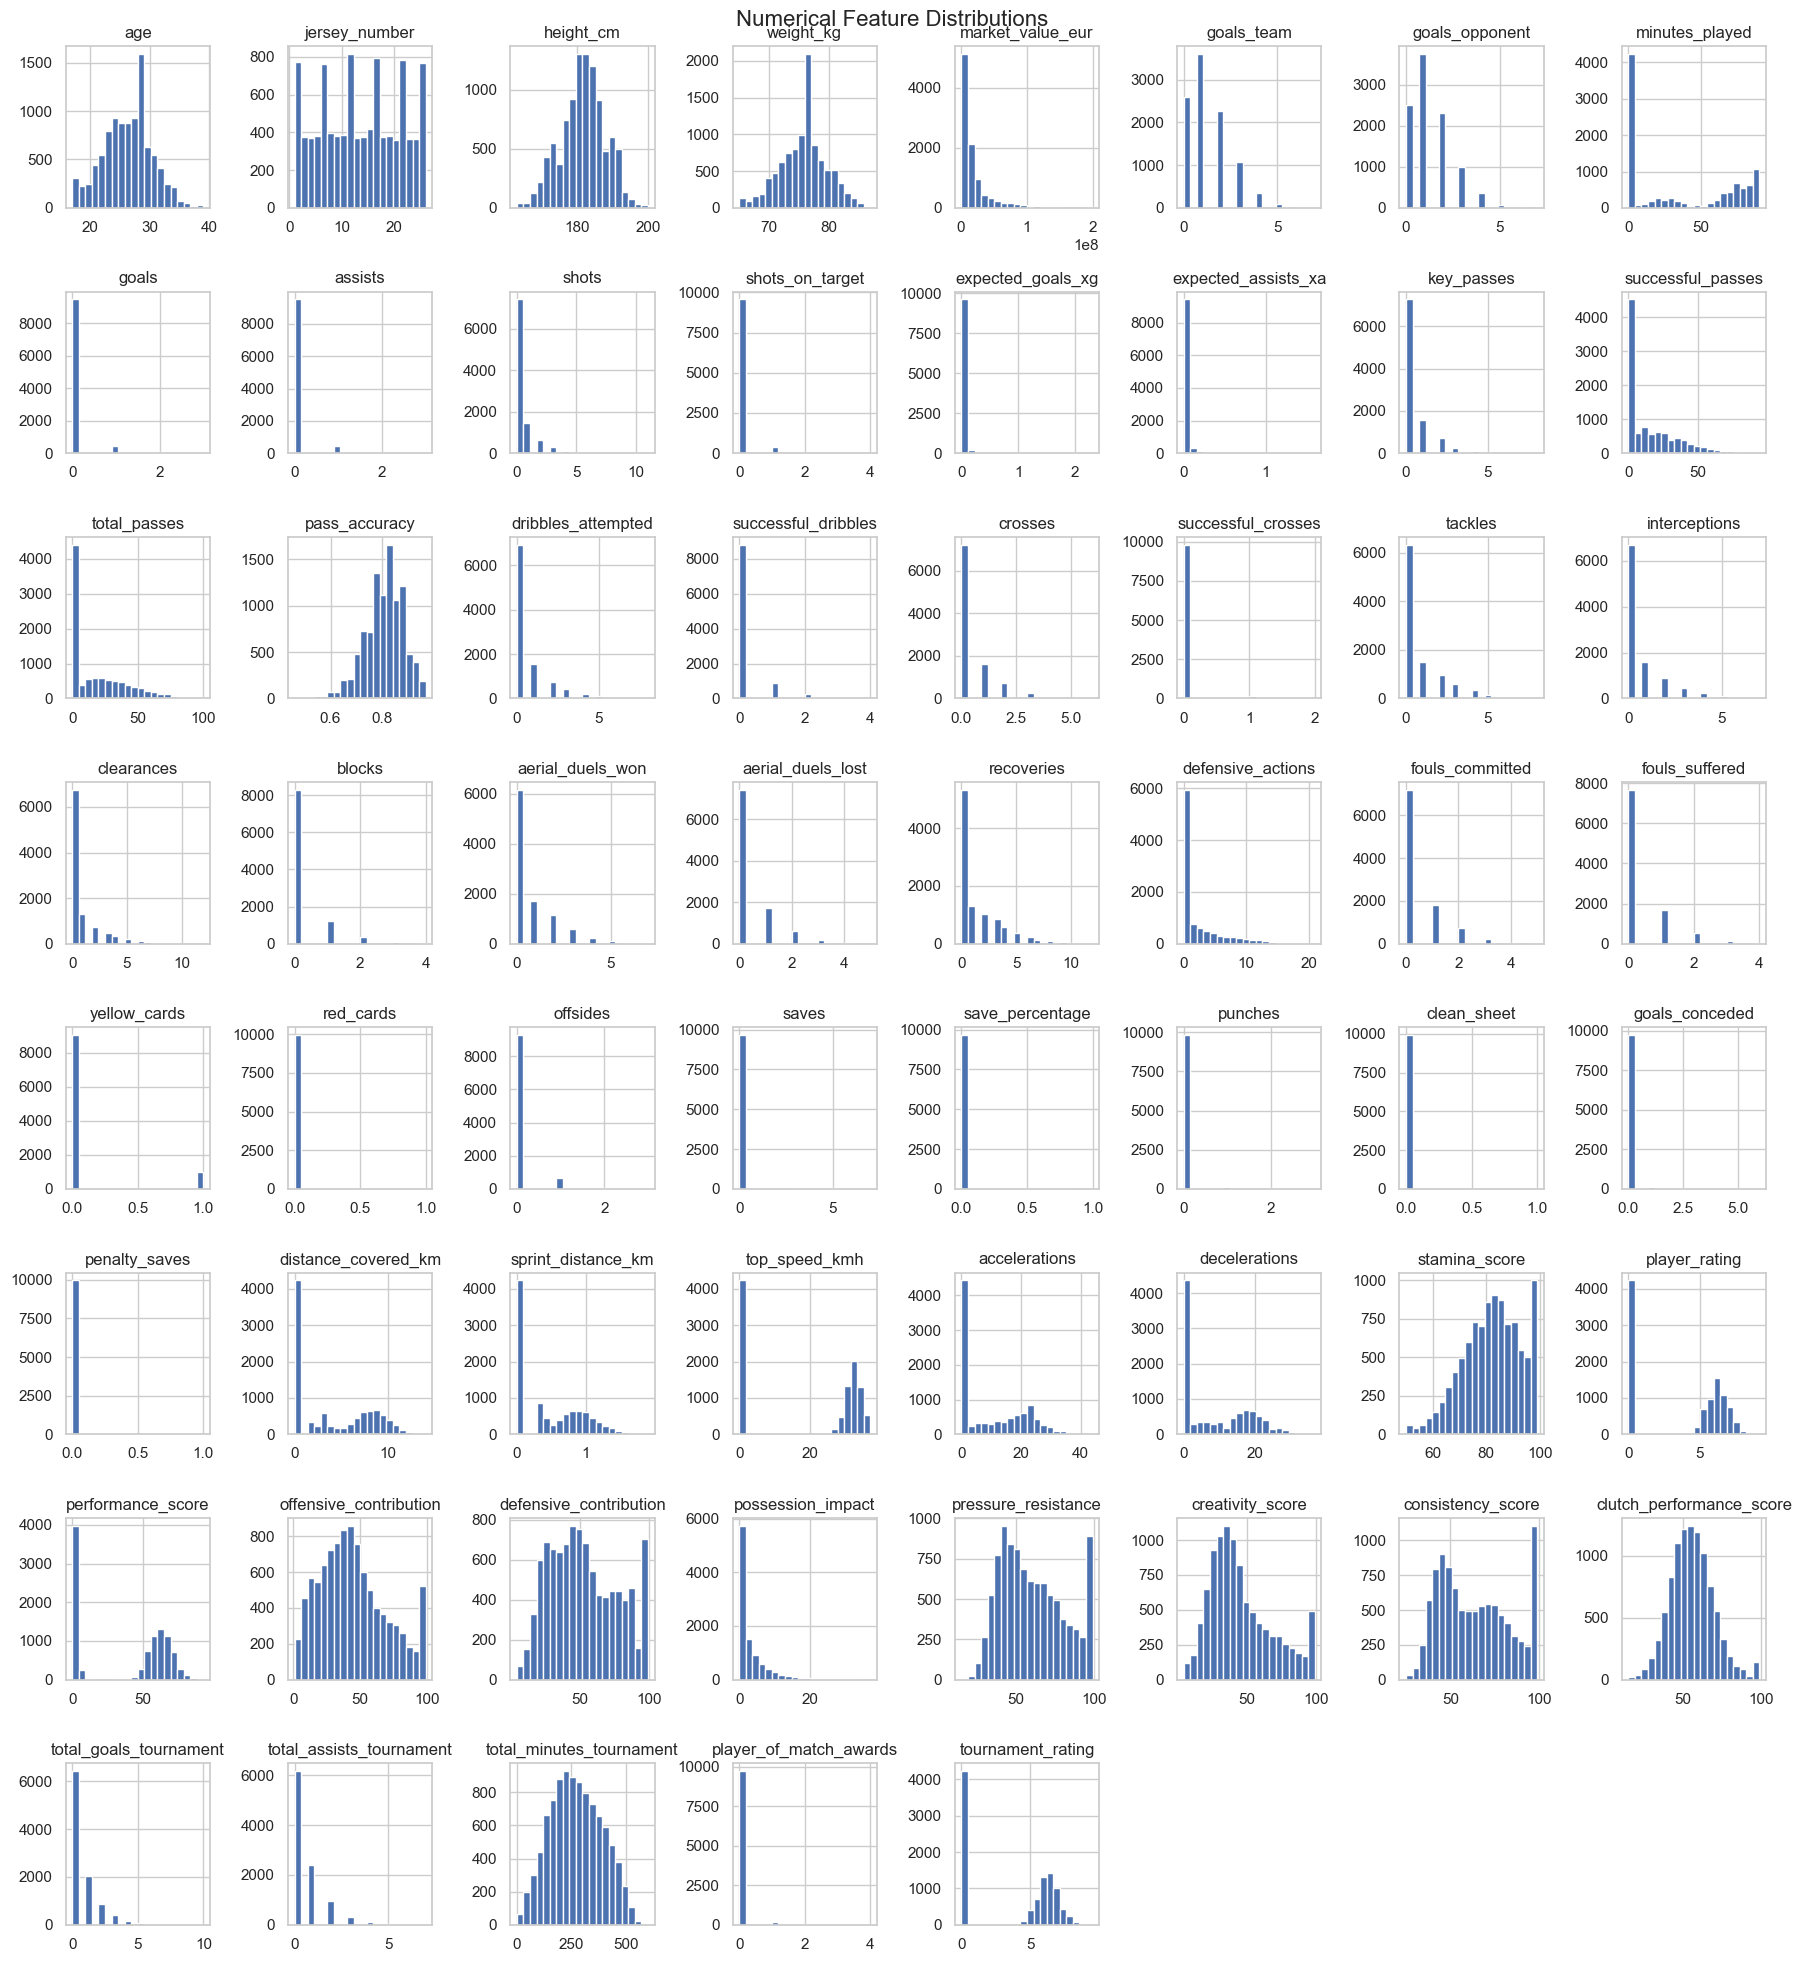

In [4]:
# 2.3 Numerical feature distributions
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].sample(min(10000, len(df)), random_state=42).hist(figsize=(18,20), bins=20)
plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

In [5]:
# 2.4 Categorical feature distributions
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print('\n', col)
    print(df[col].value_counts().head(10))


 player_id
player_id
P00937    66
P00946    66
P00957    66
P00941    66
P00945    66
P00951    66
P00949    66
P00944    66
P00958    66
P00956    66
Name: count, dtype: int64

 player_name
player_name
Pierre-Emile Christensen    86
Kalidou Mendy               76
Hee-chan Hwang              68
Akram Ali                   66
Ahmed Al-Dosari             66
Akram Al-Ahmad              66
Almoez Muntari              66
Abdelaziz Ismaeel           66
Hassan Al-Nobi              66
Akram Mesa                  66
Name: count, dtype: int64

 nationality
nationality
Qatari      1716
Jamaican    1534
Moroccan    1430
Dutch       1404
Italian     1378
Saudi       1352
Belgian     1326
Turkish     1300
Scottish    1274
Croatian    1274
Name: count, dtype: int64

 team
team
Qatar           1716
Jamaica         1534
Morocco         1430
Netherlands     1404
Italy           1378
Saudi Arabia    1352
Belgium         1326
Turkey          1300
Scotland        1274
Croatia         1274
Name: count, dty

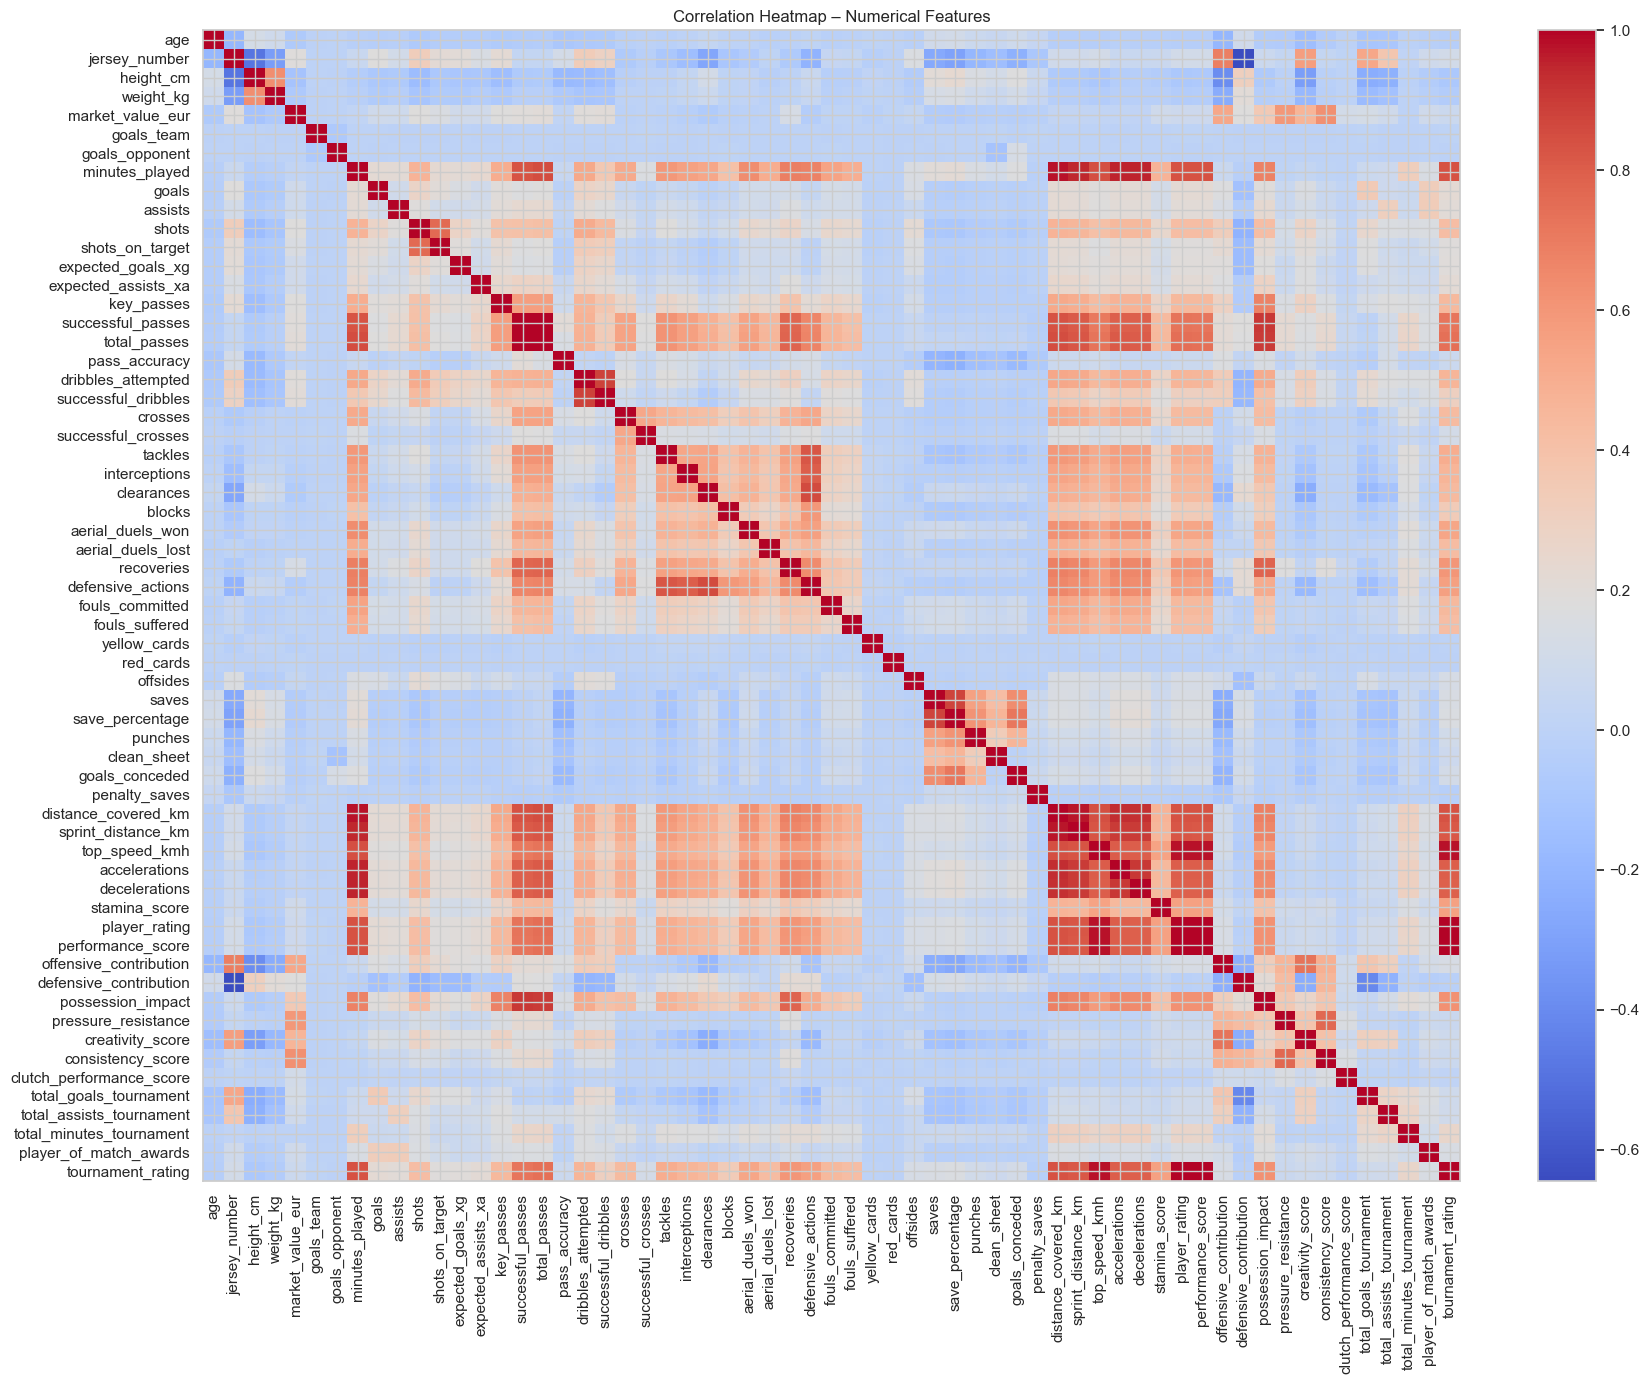

In [6]:
# 2.5 Correlation heatmap for numerical variables
plt.figure(figsize=(18,14))
corr = df[numeric_cols].corr()
plt.imshow(corr, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation Heatmap – Numerical Features')
plt.tight_layout()
plt.show()

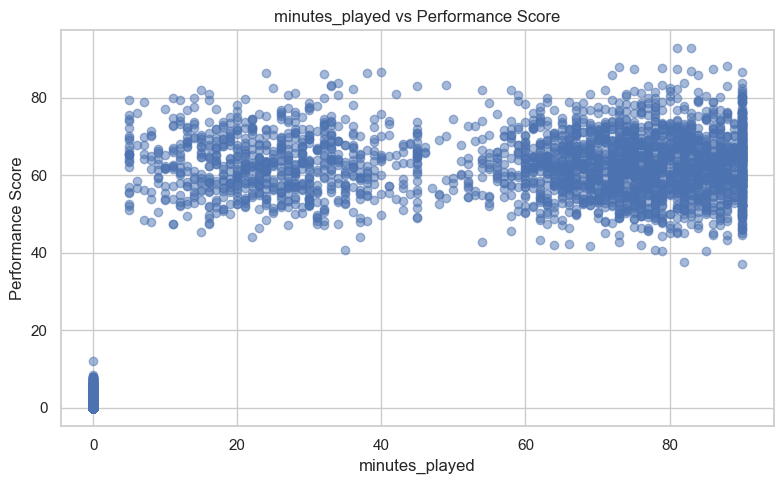

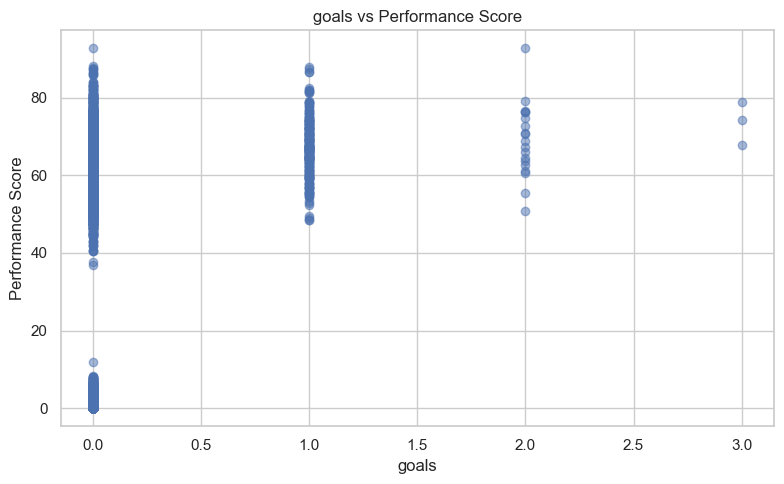

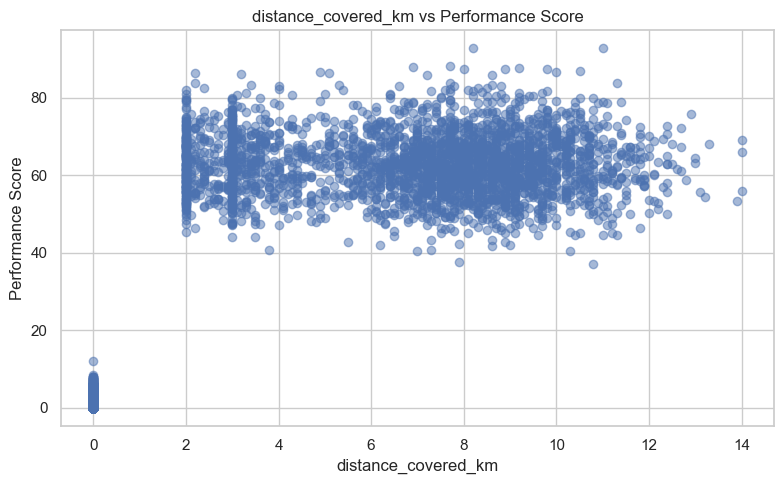

In [7]:
# 2.6 Feature-target relationship plots
for col in ['minutes_played', 'goals', 'distance_covered_km']:
    plt.figure(figsize=(8,5))
    sample_plot = df.sample(min(5000, len(df)), random_state=42)
    plt.scatter(sample_plot[col], sample_plot['performance_score'], alpha=0.5)
    plt.title(f'{col} vs Performance Score')
    plt.xlabel(col)
    plt.ylabel('Performance Score')
    plt.tight_layout()
    plt.show()

In [8]:
# 3.1 Remove duplicate records and create date-based features
df = df.drop_duplicates().copy()

df['match_date'] = pd.to_datetime(df['match_date'], errors='coerce')
df['match_year'] = df['match_date'].dt.year
df['match_month'] = df['match_date'].dt.month
df.drop(columns=['match_date'], inplace=True)

print('Shape after duplicate removal:', df.shape)
print('Missing values after date conversion:', df.isnull().sum().sum())

Shape after duplicate removal: (54600, 76)
Missing values after date conversion: 0


In [9]:
# 3.2 Create domain-based engineered features
df['goal_contribution_rate'] = (df['goals'] + df['assists']) / (df['minutes_played'].replace(0, np.nan) / 90)
df['work_rate_intensity'] = df['sprint_distance_km'] / (df['distance_covered_km'] + 0.001)
df['passing_efficiency'] = df['successful_passes'] / (df['total_passes'] + 1)

df = df.replace([np.inf, -np.inf], np.nan)

print(df[['goal_contribution_rate', 'work_rate_intensity', 'passing_efficiency']].describe().T)

                          count      mean       std  min  25%       50%  \
goal_contribution_rate  31558.0  0.269057  0.783636  0.0  0.0  0.000000   
work_rate_intensity     54600.0  0.067947  0.060270  0.0  0.0  0.090900   
passing_efficiency      54600.0  0.432476  0.378971  0.0  0.0  0.652174   

                             75%        max  
goal_contribution_rate  0.000000  18.000000  
work_rate_intensity     0.123058   0.166597  
passing_efficiency      0.779412   0.960396  


### Feature Engineering Justification
- **Goal contribution rate:** combines goals and assists per 90 minutes so attacking contribution is comparable across playing time.
- **Work-rate intensity:** relates sprint distance to total distance to represent movement intensity.
- **Passing efficiency:** measures successful passes relative to attempted passes and represents passing effectiveness.

In [10]:
# 3.3 Select predictors and remove identifiers/post-outcome variables
# These fields are excluded because they are identifiers or summary scores generated after the match/performance outcome.
drop_columns = [
    'player_id', 'player_name', 'match_id',
    'player_rating', 'tournament_rating',
    'offensive_contribution', 'defensive_contribution',
    'possession_impact', 'pressure_resistance',
    'creativity_score', 'consistency_score', 'clutch_performance_score',
    'total_goals_tournament', 'total_assists_tournament',
    'total_minutes_tournament', 'player_of_match_awards'
]

model_df = df.drop(columns=[c for c in drop_columns if c in df.columns]).copy()

# Use numerical predictors for the ten basic regression models.
model_df = model_df.select_dtypes(include=np.number)

X = model_df.drop(columns=['performance_score'])
y = model_df['performance_score']

print('Predictor shape:', X.shape)
print('Target shape:', y.shape)

Predictor shape: (54600, 52)
Target shape: (54600,)


In [11]:
# 3.4 Train/test split with stratification by target bins
# Bins allow a regression target to be approximately stratified across train and test sets.
y_bins = pd.qcut(y, q=10, labels=False, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y_bins
)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 43680
Testing samples: 10920


In [12]:
# 3.5 Missing-value treatment using training-set statistics only
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# IQR outlier capping: bounds are calculated from training data only.
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

X_train = X_train.clip(lower=lower, upper=upper, axis=1)
X_test = X_test.clip(lower=lower, upper=upper, axis=1)

print('Missing values in training data:', X_train.isnull().sum().sum())
print('Missing values in test data:', X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in test data: 0


In [13]:
# 3.6 Standard scaling fitted only on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled training shape:', X_train_scaled.shape)
print('Scaled testing shape:', X_test_scaled.shape)

Scaled training shape: (43680, 52)
Scaled testing shape: (10920, 52)


In [14]:
# Regression model evaluation setup
results = {}

def evaluate_model(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    predictions = model.predict(X_te)
    return {
        'Algorithm': name,
        'R2': r2_score(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'MAE': mean_absolute_error(y_test, predictions),
        'estimator': model,
        'predictions': predictions
    }


In [15]:
# 1. Linear Regression
results['1. Linear Regression'] = evaluate_model(
    '1. Linear Regression', LinearRegression(), X_train_scaled, X_test_scaled)

# 2. Ridge Regression
results['2. Ridge Regression'] = evaluate_model(
    '2. Ridge Regression', Ridge(alpha=1.0), X_train_scaled, X_test_scaled)
for name in ['1. Linear Regression', '2. Ridge Regression']:
    r=results[name]
    print(f'\n{name}')
    print(f'R² Score : {r["R2"]:.4f}')
    print(f'RMSE     : {r["RMSE"]:.4f}')
    print(f'MAE      : {r["MAE"]:.4f}')



1. Linear Regression
R² Score : 0.9641
RMSE     : 5.8860
MAE      : 4.1699

2. Ridge Regression
R² Score : 0.9641
RMSE     : 5.8860
MAE      : 4.1703


In [16]:
# 3. Lasso Regression
results['3. Lasso Regression'] = evaluate_model(
    '3. Lasso Regression', Lasso(alpha=0.05, max_iter=10000), X_train_scaled, X_test_scaled)

# 4. ElasticNet Regression
results['4. ElasticNet Regression'] = evaluate_model(
    '4. ElasticNet Regression', ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=10000), X_train_scaled, X_test_scaled)
for name in ['3. Lasso Regression', '4. ElasticNet Regression']:
    r=results[name]
    print(f'\n{name}')
    print(f'R² Score : {r["R2"]:.4f}')
    print(f'RMSE     : {r["RMSE"]:.4f}')
    print(f'MAE      : {r["MAE"]:.4f}')



3. Lasso Regression
R² Score : 0.9626
RMSE     : 6.0092
MAE      : 4.2944

4. ElasticNet Regression
R² Score : 0.9612
RMSE     : 6.1229
MAE      : 4.4073


In [17]:
# 5. Polynomial Regression
poly_features = ['minutes_played', 'goals', 'assists', 'distance_covered_km', 'expected_goals_xg']
poly_idx = [X.columns.get_loc(c) for c in poly_features if c in X.columns]

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled[:, poly_idx])
X_test_poly = poly.transform(X_test_scaled[:, poly_idx])

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
poly_pred = poly_model.predict(X_test_poly)

results['5. Polynomial Regression'] = {
    'Algorithm': '5. Polynomial Regression',
    'R2': r2_score(y_test, poly_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, poly_pred)),
    'MAE': mean_absolute_error(y_test, poly_pred),
    'estimator': poly_model,
    'predictions': poly_pred
}
r=results['5. Polynomial Regression']
print(f'\n{r["Algorithm"]}')
print(f'R² Score : {r["R2"]:.4f}')
print(f'RMSE     : {r["RMSE"]:.4f}')
print(f'MAE      : {r["MAE"]:.4f}')



5. Polynomial Regression
R² Score : 0.9039
RMSE     : 9.6363
MAE      : 6.7128
